In [1]:
!pip install pyspark

In [2]:
from pyspark.sql import SparkSession

#tworzenie sesji Spark
spark = SparkSession.builder.appName("Analiza zamówień").getOrCreate()

In [3]:
from os import sched_param
from pyspark.sql.types import StructType, StructField, StringType, IntegerType, DoubleType


#tworzenie schematu
schema = StructType([
    StructField("order_id", IntegerType(), True),
    StructField("customer_id", IntegerType(), True),
    StructField("category", StringType(), True),
    StructField("amount", DoubleType(), True),
])

In [5]:
data = [
    (1,101,"electronics",299.99),
    (2,102,"books",16.22),
    (3,103,"books",31.00),
    (4,104,"electronics",425.00),
    (5,107,"clothing",88.54),
    (6,108,"books",189.00),
]

In [6]:
df = spark.createDataFrame(data, schema)
df.show()

+--------+-----------+-----------+------+
|order_id|customer_id|   category|amount|
+--------+-----------+-----------+------+
|       1|        101|electronics|299.99|
|       2|        102|      books| 16.22|
|       3|        103|      books|  31.0|
|       4|        104|electronics| 425.0|
|       5|        107|   clothing| 88.54|
|       6|        108|      books| 189.0|
+--------+-----------+-----------+------+



In [7]:
df.filter(df["amount"]>100).show()

+--------+-----------+-----------+------+
|order_id|customer_id|   category|amount|
+--------+-----------+-----------+------+
|       1|        101|electronics|299.99|
|       4|        104|electronics| 425.0|
|       6|        108|      books| 189.0|
+--------+-----------+-----------+------+



In [8]:
avg_by_category = df.groupBy("category").agg({"amount": "avg"})
avg_by_category.show()

+-----------+-----------+
|   category|avg(amount)|
+-----------+-----------+
|      books|      78.74|
|electronics|    362.495|
|   clothing|      88.54|
+-----------+-----------+



In [9]:
#konwersja do Pandas
pdf = avg_by_category.toPandas()

In [10]:
import matplotlib.pyplot as plt

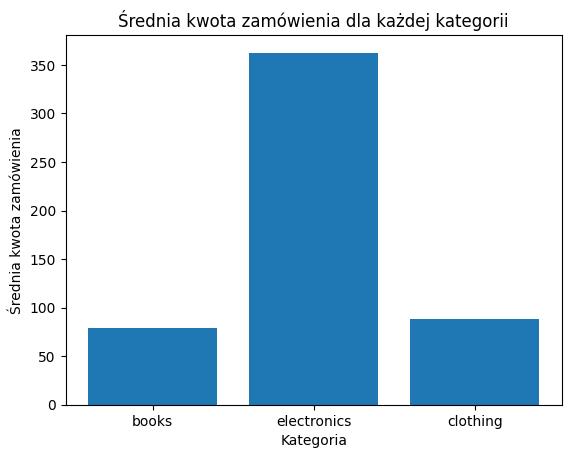

In [11]:
plt.bar(pdf["category"], pdf["avg(amount)"])
plt.xlabel("Kategoria")
plt.ylabel("Średnia kwota zamówienia")
plt.title("Średnia kwota zamówienia dla każdej kategorii")
plt.show()
#